In [25]:
import os.path as op

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from neuron import h
from neuron.units import ms, mV
from scipy import signal
from scipy.signal import find_peaks
from scipy.optimize import curve_fit
from matplotlib.gridspec import GridSpec

import pandas as pd

from hnn_tuning import ALLEN_DATA, HNN_CORE_MOD, results_dir
from hnn_tuning.cell_builder_utils import Cell, _get_inh_soma
from hnn_tuning.inh_mechs_utils import Mechs as inhmechs
from hnn_tuning.plot_utils import get_cmap_neurons
from hnn_tuning.model_data_comparison import exp_func, load_ephys_csv

pth_mod = str(HNN_CORE_MOD)
pth_data = "/Users/katharinaduecker/Documents/projects_brown/human_patchseq_gaba/data"

In [26]:
meta2 = pd.read_csv(op.join(pth_data, "LeeDalley_manuscript_metadata_v2.csv"))
morpho = pd.read_csv(op.join(pth_data, "LeeDalley_morpho_features.csv"))
ephys = pd.read_csv(op.join(pth_data, "LeeDalley_ephys_fx.csv"))
cell_types_db = pd.read_csv("/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/data/allen-data/cell_types_specimen_details.csv")
acute_specimen = meta2[meta2["condition"] == "acute"]
acute_specimen

,specimen_id_x,cell_name,Donor,structure,lobe,disease_category,Transcriptomic_type,M_H_Hodge_cross_species_types,condition,condition2,...,Qualitative_morphology_type,Cortical_layer,subclass_label,Revised_subclass_label,Virus,Genes_Detected,patched_cell_container,marker_sum_norm_label,broad_class_label,nwb_id
0,567737682,H17.06.003.11.06.02,H17.06.003,MTG,TemL,epilepsy,Inh L1-2 ADARB2 MC4R,NaN,acute,acute_microglial,...,NaN,3,LAMP5/PAX6/Other,VIP,NaN,12590,P1S4_170131_002_A01,1.008055,GABAergic neuron,NaN
1,567773648,H17.06.003.11.07.07,H17.06.003,MTG,TemL,epilepsy,Inh L2-6 VIP QPCT,NaN,acute,acute,...,NaN,2,VIP,VIP,NaN,4436,P2S4_170131_058_A01,0.917720,GABAergic neuron,NaN
2,569871062,H17.03.002.11.09.08,H17.03.002,MTG,TemL,epilepsy,Inh L1 SST NMBR,NaN,acute,acute,...,NaN,1,LAMP5/PAX6/Other,VIP,NaN,5275,P1S4_170214_008_A01,0.945215,GABAergic neuron,NaN
3,571674365,H17.06.006.11.04.06,H17.06.006,MTG,TemL,epilepsy,Inh L1-2 PAX6 CDH12,NaN,acute,acute,...,NaN,NaN,LAMP5/PAX6/Other,LAMP5/PAX6/Other,NaN,5016,P1S4_170301_006_A01,0.819044,GABAergic neuron,NaN
4,588160377,H17.03.005.11.15.07,H17.03.005,MTG,TemL,epilepsy,Inh L1-2 PAX6 CDH12,NaN,acute,acute,...,NaN,NaN,LAMP5/PAX6/Other,LAMP5/PAX6/Other,NaN,2071,P5S4_170509_207_A01,0.476006,GABAergic neuron,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
712,1061426228,H20.29.181.11.61.05,H20.29.181,FroL,FroL,epilepsy,Inh L1-3 VIP CCDC184,NaN,acute,acute_microglial,...,NaN,3,VIP,VIP,NaN,3583,PHS4_200819_602_A01,0.656310,GABAergic neuron,1.219764e+09
765,1089078118,H21.03.305.11.06.01.04,H21.03.305,TemL,TemL,epilepsy,Inh L2-4 VIP SPAG17,NaN,acute,acute_microglial,...,NaN,3,VIP,VIP,NaN,7726,PAS4_210309_456_A01,1.401961,GABAergic neuron,1.089078e+09
766,1099849087,H21.29.193.11.11.01,H21.29.193,TemL,TemL,epilepsy,Inh L2-6 LAMP5 CA1,NaN,acute,acute,...,NaN,2,LAMP5/PAX6/Other,LAMP5/PAX6/Other,NaN,2794,PHS4_210317_101_A01,0.756957,GABAergic neuron,NaN
774,685821059,H18.03.008.11.12.09,H18.03.008,MTG,TemL,epilepsy,Inh L4-5 PVALB MEPE,NaN,acute,acute,...,NaN,4,PVALB,PVALB,NaN,5239,P8S4_180417_367_A01,0.857831,GABAergic neuron,6.858210e+08


In [27]:
# we won't have individual traces ...
for ep in ephys["specimen_id"]:
    if ep in list(cell_types_db["specimen__id"]):
        print(ep)

In [28]:
smart_seq = pd.read_csv(op.join(pth_data, "human_smart_seq.csv"))       # Hodge et al., 2019 https://www.nature.com/articles/s41586-019-1506-7         https://celltypes.brain-map.org/ rna-seq data

In [33]:
genes = pd.read_csv(op.join(pth_data, "vgic_genes.csv"), encoding="mac_roman")
channel_genes = genes["HGNC symbol"]
model_map = genes.drop_duplicates().set_index("HGNC symbol")["Model"]

## VIP
smart_seq_channels = smart_seq[smart_seq["feature"].isin(channel_genes)]
vip = smart_seq.columns[smart_seq.columns.str.contains("VIP")]

# non-zero expression
expr = smart_seq_channels.set_index("feature")
cpm = 2**expr[vip] -1

# find the cells for which cpm > 0.5 in 50% of the layers. This is a rule of thumb. Although the authors make it more complicated here,https://f1000research.com/articles/5-1438
frac_expressed = (cpm > 0.5).mean(axis=1)
vip_cpm_expr = cpm.loc[frac_expressed >= 0.5]

# map onto model
vip_cpm_expr = vip_cpm_expr.copy()
vip_cpm_expr.insert(0, "model", vip_cpm_expr.index.map(model_map))
vip_cpm_expr["model"] = vip_cpm_expr["model"].fillna("unassigned")

## PV
smart_seq_channels = smart_seq[smart_seq["feature"].isin(channel_genes)]
vip = smart_seq.columns[smart_seq.columns.str.contains("PV")]

# non-zero expression
expr = smart_seq_channels.set_index("feature")
cpm = 2**expr[vip] -1

# find the cells for which cpm > 0.5 in 50% of the layers. This is a rule of thumb. Although the authors make it more complicated here,https://f1000research.com/articles/5-1438
frac_expressed = (cpm > 0.5).mean(axis=1)
pv_cpm_expr = cpm.loc[frac_expressed >= 0.5]

# map onto model
pv_cpm_expr = pv_cpm_expr.copy()
pv_cpm_expr.insert(0, "model", pv_cpm_expr.index.map(model_map))
pv_cpm_expr["model"] = pv_cpm_expr["model"].fillna("unassigned")

## SST

smart_seq_channels = smart_seq[smart_seq["feature"].isin(channel_genes)]
sst = smart_seq.columns[smart_seq.columns.str.contains("PV")]

# non-zero expression
expr = smart_seq_channels.set_index("feature")
cpm = 2**expr[sst] -1

# find the cells for which cpm > 0.5 in 50% of the layers. This is a rule of thumb. Although the authors make it more complicated here,https://f1000research.com/articles/5-1438
frac_expressed = (cpm > 0.5).mean(axis=1)
sst_cpm_expr = cpm.loc[frac_expressed >= 0.5]

# map onto model
sst_cpm_expr = sst_cpm_expr.copy()
sst_cpm_expr.insert(0, "model", sst_cpm_expr.index.map(model_map))
sst_cpm_expr["model"] = sst_cpm_expr["model"].fillna("unassigned")


/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_37308/2633965142.py:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


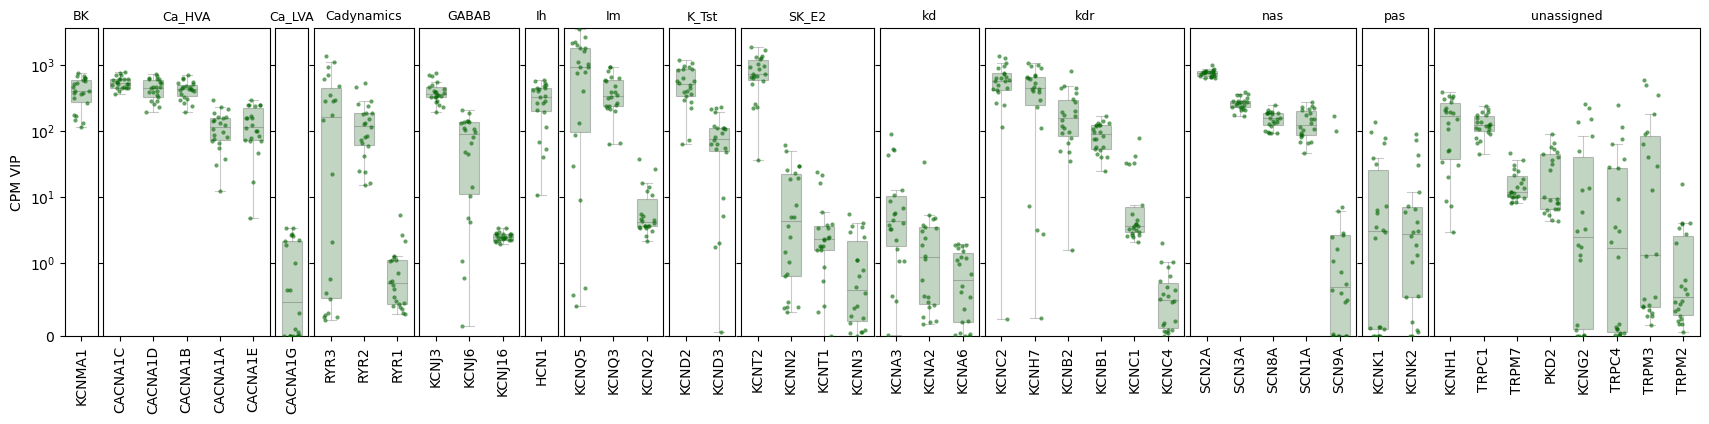

In [30]:
## PLOT VIP

value_cols = vip_cpm_expr.columns.drop("model")

# Long format: keep model as an identifier column
long = (vip_cpm_expr
        .reset_index()
        .melt(id_vars=["feature", "model"], var_name="cell", value_name="cpm"))

# Gene order within each model: by median expression
medians = vip_cpm_expr[value_cols].median(axis=1)
models = sorted(vip_cpm_expr["model"].unique())
orders = {m: medians[vip_cpm_expr["model"] == m].sort_values(ascending=False).index
          for m in models}

fig, axes = plt.subplots(
    1, len(models), sharey=True,
    figsize=(max(6, 0.3 * len(vip_cpm_expr) + 0.5 * len(models)), 4),
    gridspec_kw={"width_ratios": [len(orders[m]) for m in models], "wspace": 0.05},
    squeeze=False,
)
axes = axes[0]

for ax, m in zip(axes, models):
    sub = long[long["model"] == m]
    sns.boxplot(data=sub, x="feature", y="cpm", order=orders[m],
                showfliers=False, width=0.6, color="#006400", boxprops=dict(alpha=0.25),
                whiskerprops=dict(alpha=0.24),
                capprops=dict(alpha=0.24),
                medianprops=dict(alpha=0.24),
                linewidth=0.8, ax=ax)
    sns.stripplot(data=sub, x="feature", y="cpm", order=orders[m],
                  jitter=0.25, size=3, alpha=0.6, ax=ax, color="#006400")
    ax.set_title(m, fontsize=9)
    ax.tick_params(axis="x", rotation=90)
    ax.set_xlabel("")
    ax.set_ylabel("")

axes[0].set_ylabel("CPM VIP")
axes[0].set_yscale("symlog", linthresh=1)  # handles zeros, log-like above 1
axes[0].set_ylim(bottom=0)
plt.tight_layout()
plt.show()

/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_37308/3012058448.py:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


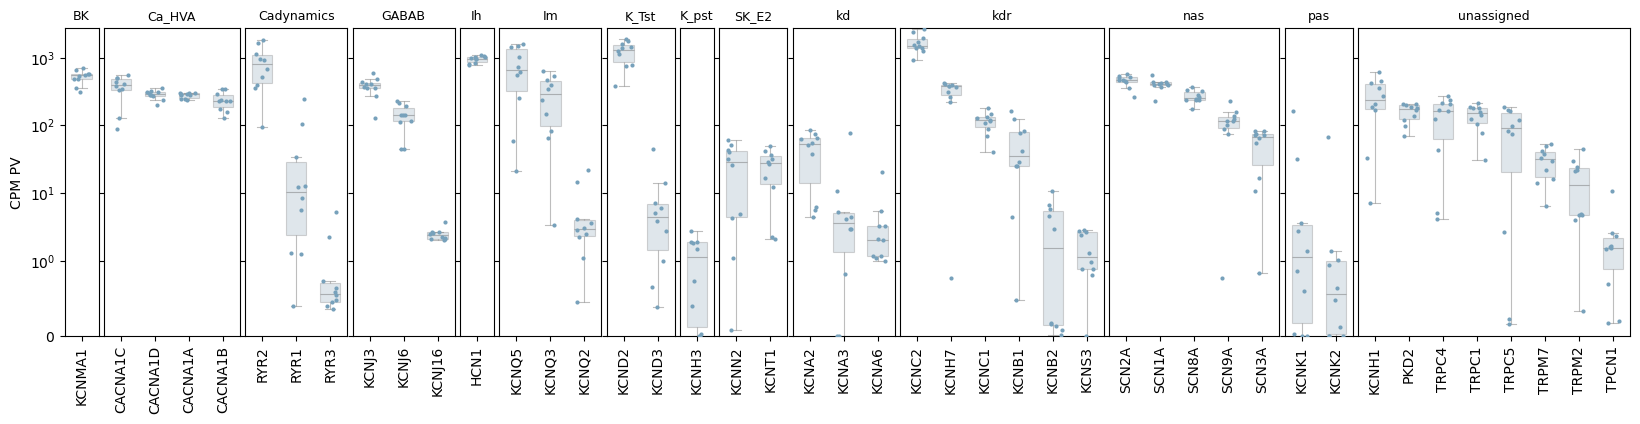

In [31]:
## PLOT PV

value_cols = pv_cpm_expr.columns.drop("model")

# Long format: keep model as an identifier column
long = (pv_cpm_expr
        .reset_index()
        .melt(id_vars=["feature", "model"], var_name="cell", value_name="cpm"))

# Gene order within each model: by median expression
medians = pv_cpm_expr[value_cols].median(axis=1)
models = sorted(pv_cpm_expr["model"].unique())
orders = {m: medians[pv_cpm_expr["model"] == m].sort_values(ascending=False).index
          for m in models}

fig, axes = plt.subplots(
    1, len(models), sharey=True,
    figsize=(max(6, 0.3 * len(pv_cpm_expr) + 0.5 * len(models)), 4),
    gridspec_kw={"width_ratios": [len(orders[m]) for m in models], "wspace": 0.05},
    squeeze=False,
)
axes = axes[0]

for ax, m in zip(axes, models):
    sub = long[long["model"] == m]
    sns.boxplot(data=sub, x="feature", y="cpm", order=orders[m],
                showfliers=False, width=0.6, color="#77a1bb", boxprops=dict(alpha=0.25),
                whiskerprops=dict(alpha=0.4),
                capprops=dict(alpha=0.4),
                medianprops=dict(alpha=0.4),
                linewidth=0.8, ax=ax)
    sns.stripplot(data=sub, x="feature", y="cpm", order=orders[m],
                  jitter=0.25, size=3, alpha=1, ax=ax, color="#77a1bb")
    ax.set_title(m, fontsize=9)
    ax.tick_params(axis="x", rotation=90)
    ax.set_xlabel("")
    ax.set_ylabel("")

axes[0].set_ylabel("CPM PV")
axes[0].set_yscale("symlog", linthresh=1)  # handles zeros, log-like above 1
axes[0].set_ylim(bottom=0)
plt.tight_layout()
plt.show()

/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_37308/3245857223.py:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


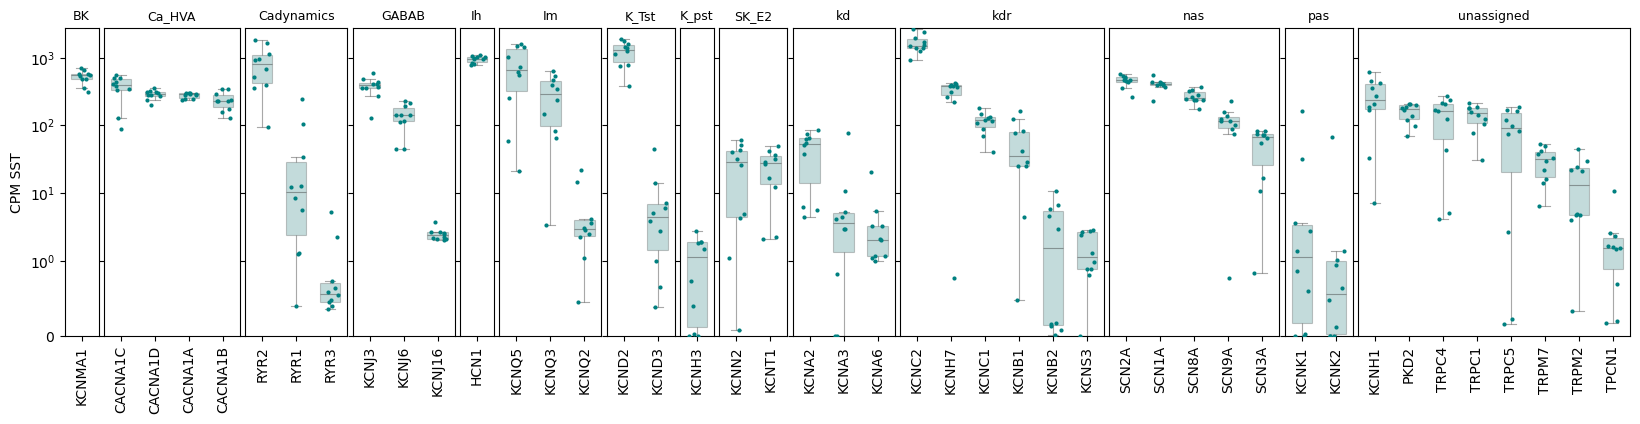

In [35]:
## PLOT SST

value_cols = sst_cpm_expr.columns.drop("model")

# Long format: keep model as an identifier column
long = (sst_cpm_expr
        .reset_index()
        .melt(id_vars=["feature", "model"], var_name="cell", value_name="cpm"))

# Gene order within each model: by median expression
medians = sst_cpm_expr[value_cols].median(axis=1)
models = sorted(sst_cpm_expr["model"].unique())
orders = {m: medians[sst_cpm_expr["model"] == m].sort_values(ascending=False).index
          for m in models}

fig, axes = plt.subplots(
    1, len(models), sharey=True,
    figsize=(max(6, 0.3 * len(sst_cpm_expr) + 0.5 * len(models)), 4),
    gridspec_kw={"width_ratios": [len(orders[m]) for m in models], "wspace": 0.05},
    squeeze=False,
)
axes = axes[0]

for ax, m in zip(axes, models):
    sub = long[long["model"] == m]
    sns.boxplot(data=sub, x="feature", y="cpm", order=orders[m],
                showfliers=False, width=0.6, color="#008080", boxprops=dict(alpha=0.25),
                whiskerprops=dict(alpha=0.4),
                capprops=dict(alpha=0.4),
                medianprops=dict(alpha=0.4),
                linewidth=0.8, ax=ax)
    sns.stripplot(data=sub, x="feature", y="cpm", order=orders[m],
                  jitter=0.25, size=3, alpha=1, ax=ax, color="#008080")
    ax.set_title(m, fontsize=9)
    ax.tick_params(axis="x", rotation=90)
    ax.set_xlabel("")
    ax.set_ylabel("")

axes[0].set_ylabel("CPM SST")
axes[0].set_yscale("symlog", linthresh=1)  # handles zeros, log-like above 1
axes[0].set_ylim(bottom=0)
plt.tight_layout()
plt.show()